In [13]:
import json
from matplotlib import pyplot as plt
import numpy as np
from src.mesh_solver import generate_naca4

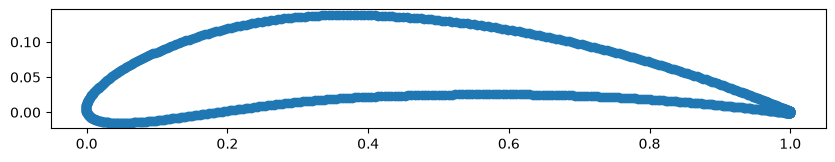

In [14]:
airfoil_code = "8412"
chord_length = 1.0  # 1 meter long
n_surface_points = 320

discretized_surface_points = generate_naca4(airfoil_code, chord=chord_length, points=n_surface_points)

ax = plt.subplots(1, 1, figsize=(10, 5))[1]

ax.plot(discretized_surface_points[:, 0], discretized_surface_points[:, 1], 'o-', label=f'NACA {airfoil_code}')
ax.set_aspect("equal")
plt.show()

[+] Convergence error plot saved to convergence_error_plot.png


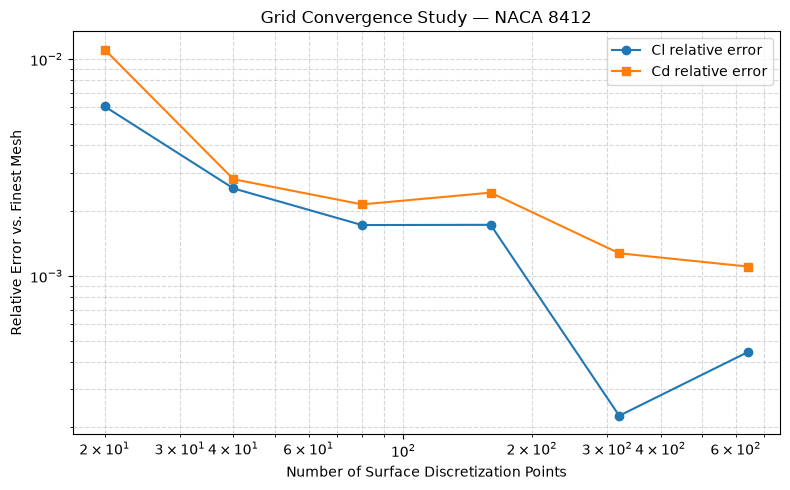

In [ ]:

with open("convergence_results_keep.json") as f:
    data = json.load(f)

def plot_convergence(results, airfoil_code):
    if not results or len(results) < 2:
        print("\n[-] Error: Not enough successful data points to plot convergence.")
        return

    plt.close('all')
    results_sorted = sorted(results, key=lambda r: r['points'])
    pts_axis = np.array([r['points'] for r in results_sorted])

    # Use the finest mesh as the reference "truth" value
    cl_ref = results_sorted[-1]['Cl']
    cd_ref = results_sorted[-1]['Cd']

    cl_err = np.array([abs(r['Cl'] - cl_ref) / abs(cl_ref) for r in results_sorted[:-1]])
    cd_err = np.array([abs(r['Cd'] - cd_ref) / abs(cd_ref) for r in results_sorted[:-1]])
    pts_err_axis = pts_axis[:-1]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(pts_err_axis, cl_err, 'o-', label='Cl relative error')
    ax.loglog(pts_err_axis, cd_err, 's-', label='Cd relative error')

    ax.set_xlabel('Number of Surface Discretization Points')
    ax.set_ylabel('Relative Error vs. Finest Mesh')
    ax.set_title(f'Grid Convergence Study — NACA {airfoil_code}')
    ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax.legend()

    fig.tight_layout()
    plot_path = "plots/convergence_error_plot.png"
    plt.savefig(plot_path)
    print(f"[+] Convergence error plot saved to {plot_path}")
    plt.show()



plot_convergence(data["results"], data["airfoil"])

[+] Zoomed time convergence plot saved to time_convergence_study_zoomed.png


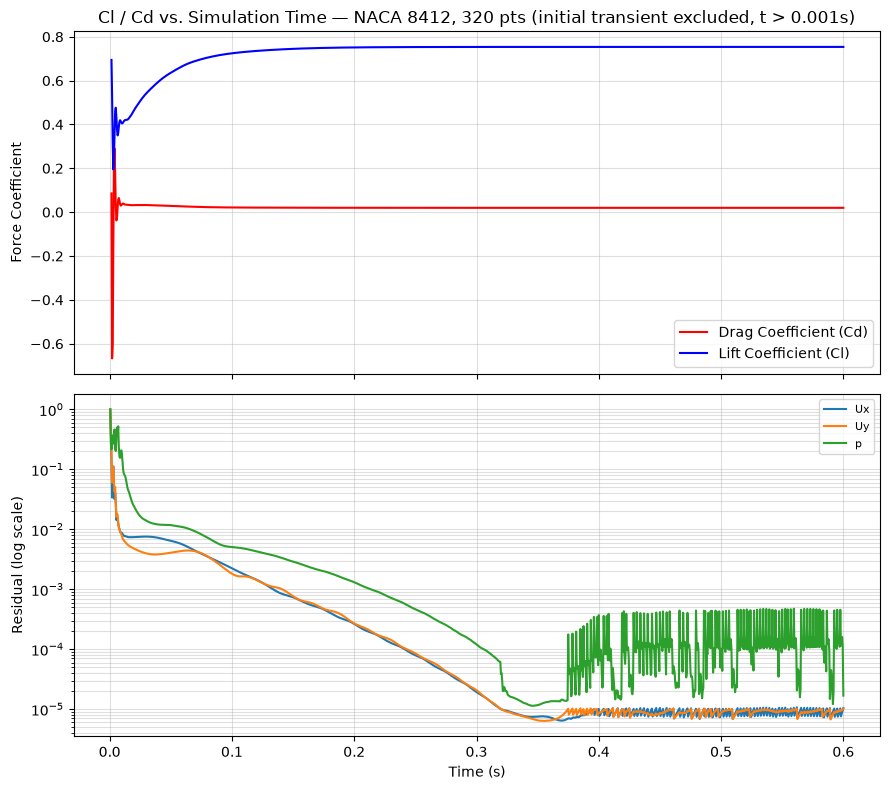


--- Convergence Summary ---
Cd stabilizes at t ≈ 0.2795
Cl stabilizes at t ≈ 0.2435


In [ ]:
# replot_time_convergence.py
import json
import numpy as np
from matplotlib import pyplot as plt

# --- Load the saved data (no rerun needed) ---
with open("time_convergence_results_320.json") as f:
    payload = json.load(f)

time = np.array(payload["time"])
cd = np.array(payload["cd"])
cl = np.array(payload["cl"])

# --- Exclude the initial impulsive-start transient so the y-axis isn't
#     squashed by the huge startup spike -- adjust this cutoff if needed ---
spike_cutoff = 0.001  # seconds
mask = time > spike_cutoff

plt.close('all')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

# --- Top panel: Cl/Cd, spike excluded ---
ax1.plot(time[mask], cd[mask], label="Drag Coefficient (Cd)", color="red")
ax1.plot(time[mask], cl[mask], label="Lift Coefficient (Cl)", color="blue")
ax1.set_ylabel("Force Coefficient")
ax1.set_title(f"Cl / Cd vs. Simulation Time — NACA {payload['airfoil']}, "
              f"{payload['points']} pts (initial transient excluded, t > {spike_cutoff}s)")
ax1.legend()
ax1.grid(True, alpha=0.4)

cd_conv_t = payload.get("cd_convergence_time")
cl_conv_t = payload.get("cl_convergence_time")
# for t, label, color in [(cd_conv_t, "Cd converged", "red"), (cl_conv_t, "Cl converged", "blue")]:
#     if t is not None and t > spike_cutoff:
#         ax1.axvline(t, linestyle="--", color=color, alpha=0.6)
#         ax1.text(t, ax1.get_ylim()[1] * 0.95, f" {label}\n t={t:.4f}s", color=color, fontsize=8)

# --- Bottom panel: residuals, full range (no need to exclude the spike here) ---
if "residual_fields" in payload:
    residual_time = np.array(payload["residual_time"])
    for col, values in payload["residual_fields"].items():
        ax2.semilogy(residual_time, values, label=col)
    # ax2.axhline(1e-4, linestyle=":", color="gray", label="1e-4 threshold")
    ax2.legend(fontsize=8)
else:
    ax2.text(0.5, 0.5, "No residuals functionObject data available",
             ha="center", va="center", transform=ax2.transAxes)

ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Residual (log scale)")
ax2.grid(True, which="both", alpha=0.4)

fig.tight_layout()
plot_path = "plots/time_convergence_study_zoomed.png"
fig.savefig(plot_path)
print(f"[+] Zoomed time convergence plot saved to {plot_path}")
plt.show()

print("\n--- Convergence Summary ---")
print(f"Cd stabilizes at t ≈ {cd_conv_t}")
print(f"Cl stabilizes at t ≈ {cl_conv_t}")

[+] Cl vs camber plot saved to camber_vs_Cl.png
[+] Cd vs camber plot saved to camber_vs_Cd.png


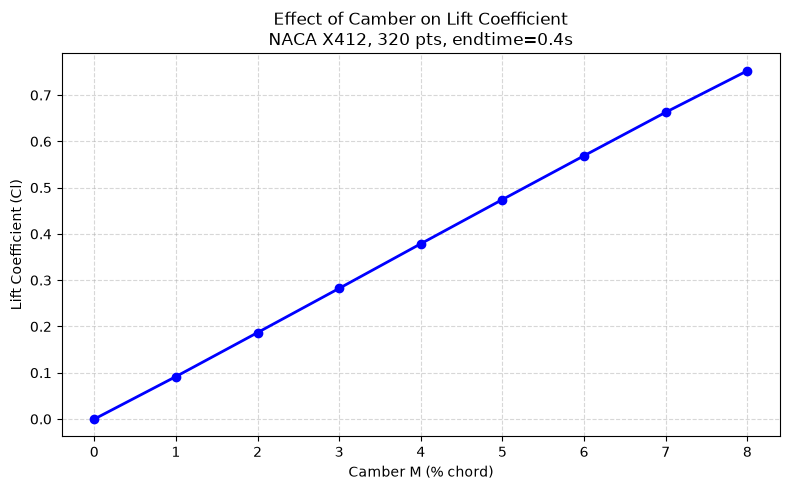

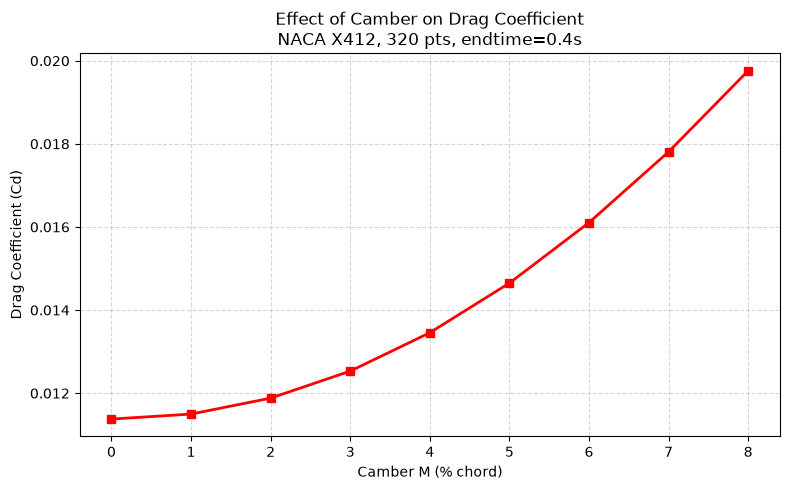

In [ ]:
# replot_camber_study.py
import json
import numpy as np
from matplotlib import pyplot as plt

# --- Load the saved results (no rerun needed) ---
with open("parameter_study_results_steady.json") as f:
    payload = json.load(f)

results_sorted = sorted(payload["results"], key=lambda r: r['m']) 
m_axis = np.array([r['m'] for r in results_sorted])
cl_axis = np.array([r['Cl'] for r in results_sorted])
cd_axis = np.array([r['Cd'] for r in results_sorted])

camber_position = payload.get("camber_position", "?")
thickness = payload.get("thickness", "?")
points = payload.get("points", "?")
endtime = payload.get("endtime", "?")

subtitle = f"NACA X{camber_position}{thickness:02d}, {points} pts, endtime={endtime}s" \
    if isinstance(thickness, int) else f"NACA X{camber_position}{thickness}, {points} pts, endtime={endtime}s"

plt.close('all')

# --- Figure 1: Cl vs camber ---
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(m_axis, cl_axis, 'o-', color='blue', linewidth=2)
ax1.set_xlabel('Camber M (% chord)')
ax1.set_ylabel('Lift Coefficient (Cl)')
ax1.set_title(f'Effect of Camber on Lift Coefficient\n{subtitle}')
ax1.grid(True, linestyle='--', alpha=0.5)
fig1.tight_layout()
cl_plot_path = "plots/camber_vs_Cl.png"
fig1.savefig(cl_plot_path)
print(f"[+] Cl vs camber plot saved to {cl_plot_path}")

# --- Figure 2: Cd vs camber ---
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.plot(m_axis, cd_axis, 's-', color='red', linewidth=2)
ax2.set_xlabel('Camber M (% chord)')
ax2.set_ylabel('Drag Coefficient (Cd)')
ax2.set_title(f'Effect of Camber on Drag Coefficient\n{subtitle}')
ax2.grid(True, linestyle='--', alpha=0.5)
fig2.tight_layout()
cd_plot_path = "camber_vs_Cd.png"
fig2.savefig(cd_plot_path)
print(f"[+] Cd vs camber plot saved to {cd_plot_path}")

plt.show()